Dataset Shape: (442, 11)

First Five Rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Correlation of Features with Target:


,Correlation
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062



New Engineered Features Added:
['BMI_BP', 'BMI_S5', 'S5_S6']

Features Selected by Correlation:
['bmi', 's5', 'bp', 's4', 's3']

Features Selected by RFE:
['bmi', 'bp', 's1', 's2', 's5']

Model Performance Comparison:


,Model,Number of Features,R2 Score,RMSE,MAE
0,Baseline - All Features,10,0.453,53.853,42.794
1,Correlation Selection,5,0.446,54.189,43.928
2,RFE Selection,5,0.438,54.557,44.025
3,Feature Engineering,13,0.476,52.695,41.879


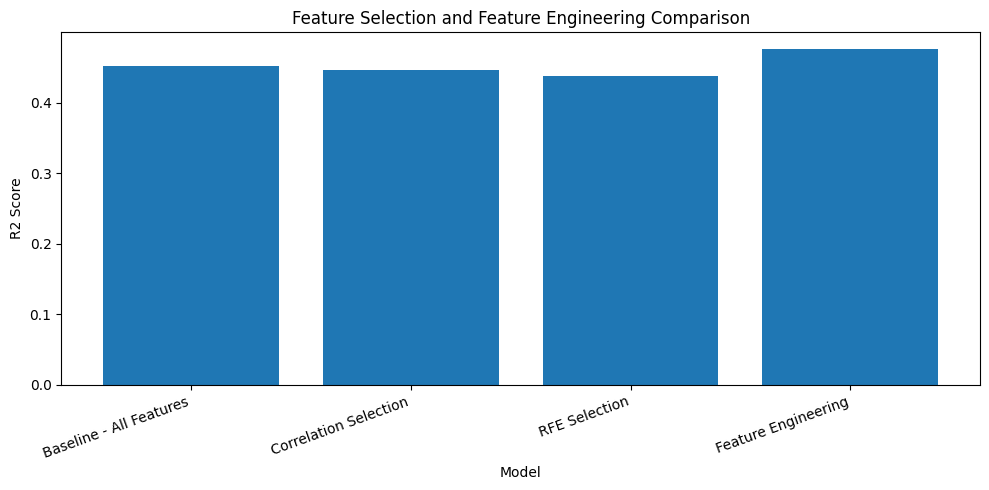

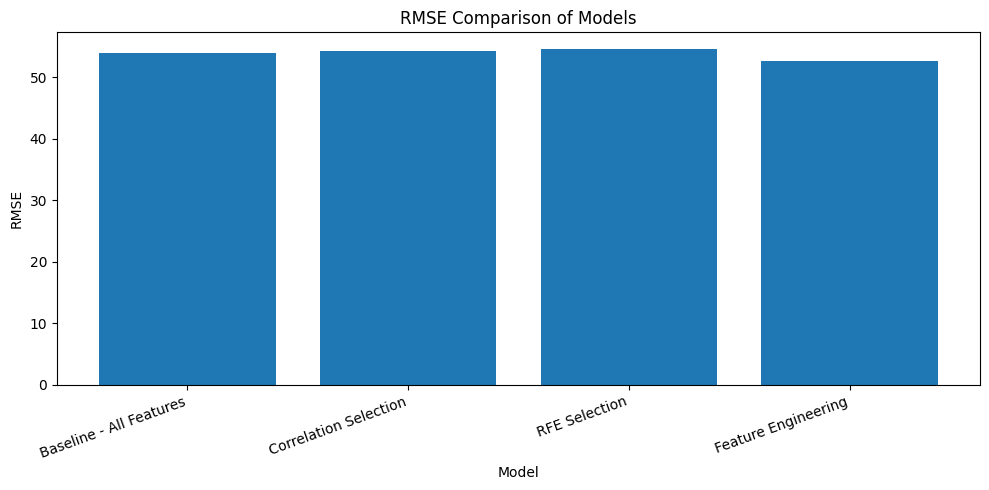

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load Dataset
data = load_diabetes(as_frame=True)
df = data.frame
X = df.drop(columns="target")
y = df["target"]

print("Dataset Shape:", df.shape)
print("\nFirst Five Rows:")
display(df.head())

# 2. Correlation Analysis
correlation = df.corr(numeric_only=True)["target"].drop("target")
correlation = correlation.reindex(
    correlation.abs().sort_values(ascending=False).index)

print("\nCorrelation of Features with Target:")
display(correlation.to_frame("Correlation"))
corr_features = correlation.abs().head(5).index.tolist()

# 3. Feature Engineering
X_eng = X.copy()
X_eng["BMI_BP"] = X_eng["bmi"] * X_eng["bp"]
X_eng["BMI_S5"] = X_eng["bmi"] * X_eng["s5"]
X_eng["S5_S6"] = X_eng["s5"] * X_eng["s6"]

print("\nNew Engineered Features Added:")
print(["BMI_BP", "BMI_S5", "S5_S6"])

# 4. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

Xeng_train, Xeng_test, _, _ = train_test_split(
    X_eng, y, test_size=0.20, random_state=42)

# 5. Recursive Feature Elimination (RFE)
rfe = RFE(
    estimator=LinearRegression(),
    n_features_to_select=5)
rfe.fit(X_train, y_train)
rfe_features = X_train.columns[rfe.support_].tolist()

print("\nFeatures Selected by Correlation:")
print(corr_features)

print("\nFeatures Selected by RFE:")
print(rfe_features)

# 6. Model Training and Evaluation
def evaluate_model(name, Xtr, Xte):
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())])
    model.fit(Xtr, y_train)
    predictions = model.predict(Xte)

    return {
        "Model": name,
        "Number of Features": Xtr.shape[1],
        "R2 Score": r2_score(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions)}
results = []

results.append(evaluate_model(
    "Baseline - All Features",
    X_train, X_test))

results.append(evaluate_model(
    "Correlation Selection",
    X_train[corr_features], X_test[corr_features]))

results.append(evaluate_model(
    "RFE Selection",
    X_train[rfe_features], X_test[rfe_features]))

results.append(evaluate_model(
    "Feature Engineering",
    Xeng_train, Xeng_test))
results_df = pd.DataFrame(results)

# 7. Display Performance Comparison
print("\nModel Performance Comparison:")
display(results_df.round(3))

# 8. Plot R2 Scores
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("Feature Selection and Feature Engineering Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# 9. Plot RMSE Scores
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("RMSE Comparison of Models")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()